# 探索性数据分析：多源异构数据下的上市公司违规预警

本课题旨在利用 CSMAR 数据库中的多维度特征，构建基于**垂直联邦学习 (Vertical Federated Learning, VFL)** 的上市公司违规预测模型。

在传统的违规预测中，仅靠单一数据源（如纯财务报表）极易被公司的人为粉饰蒙蔽，导致漏报；而仅看高管调动，又难以与企业的正常重组区分，容易造成误判。真实的违规线索往往分散在不同监管机构的“数据孤岛”中。为此，本研究引入垂直联邦架构，在确保数据不出库、保护隐私合规的前提下，联合三大异构数据源：

- **X1（市场交易维度，如深交所/上交所）**：重点捕捉异常换手率与收益背离。其核心目的在于**客观反映外部资金的真实投票**，揭示违规爆发前“大资金”量价异动的市场先兆。
- **X2（财务基本面维度，如税务/银保监）**：主要观测偿债、盈利等量化指标。其核心目的在于**提供企业账面健康度的基准测量**，并作为判定其他维度是否发生“脱节与粉饰”的参照锚点。
- **X3（公司治理维度，如证监局/内控）**：聚焦高管频繁变更与内部套现。其核心目的在于**追踪内部知情人的异常避险操作**，挖掘冰冷财务数字背后的人为风险信号。

结合上述三方数据，我们接下来提取真实违规样本，观察跨域特征的时序表现错位。

In [5]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

base_dir = "."

# 1. 载入 违规标签 Y
y_path = os.path.join(base_dir, 'Y 经营违规公司名录', 'STK_Violation_Main.xlsx')
df_y = pd.read_excel(y_path)
stk_col = 'Symbol' if 'Symbol' in df_y.columns else 'Stkcd'
df_y['Stkcd_clean'] = pd.to_numeric(df_y[stk_col], errors='coerce')
df_y = df_y.dropna(subset=['Stkcd_clean'])
df_y['Stkcd_clean'] = df_y['Stkcd_clean'].astype(int).astype(str).str.zfill(6)

target_stkcd = df_y['Stkcd_clean'].iloc[0]
print(f"数据加载完成。当前抽样分析目标公司代码：【{target_stkcd}】")

/opt/miniconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


数据加载完成。当前抽样分析目标公司代码：【000002】


## 1. 跨域视角下的信息不对称性展示

下面以某上市公司的真实违规记录为例，验证在单一数据视角下容易产生的“盲区”，以及多视角协同打通的必要性。

In [6]:
# 读取 X1, X2, X3 数据
x1_path = os.path.join(base_dir, 'X1 基础信息', '个股年交易数据表', 'TRD_Year.xlsx')
x2_path = os.path.join(base_dir, 'X2 财务信息', '偿债能力', 'FI_T1.xlsx')
x3_path = os.path.join(base_dir, 'X3 监管机构信息', '董监高及相关人员持股变动情况表', 'CG_Bsmrcshd.xlsx')

def load_and_clean(path, nrows=3000):
    if not os.path.exists(path): return pd.DataFrame()
    df = pd.read_excel(path, nrows=nrows)
    col = 'Symbol' if 'Symbol' in df.columns else 'Stkcd'
    df['Stkcd_clean'] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(subset=['Stkcd_clean'])
    df['Stkcd_clean'] = df['Stkcd_clean'].astype(int).astype(str).str.zfill(6)
    return df

x1_df = load_and_clean(x1_path)
x2_df = load_and_clean(x2_path)
x3_df = load_and_clean(x3_path, nrows=5000)

x1_sub = x1_df[x1_df['Stkcd_clean'] == target_stkcd]
x2_sub = x2_df[x2_df['Stkcd_clean'] == target_stkcd]
x3_sub = x3_df[x3_df['Stkcd_clean'] == target_stkcd]

print("【X2 财务视角】：展示短期偿债能力（如流动比率等）。部分违规公司报表往往经过粉饰，表面无明显异常。")
if not x2_sub.empty:
    time_col_x2 = 'Accper' if 'Accper' in x2_sub.columns else x2_sub.columns[2]
    display(x2_sub[[time_col_x2, 'F010101A', 'F010201A', 'F010301A']].head(3))

print("\n【X3 内部治理视角】：展示核心持股人的减持操作。这里容易暴露出报表之外的内部人员非正常行为。")
if not x3_sub.empty:
    time_col_x3 = 'Scdate' if 'Scdate' in x3_sub.columns else x3_sub.columns[3]
    display(x3_sub[[time_col_x3, 'Bsmnme', 'Shcrsn']].head(3))
else:
    print("未在当前样本检测到持股异动。")

print("\n【X1 市场交易视角】：展示年度回报率及交易分布。当内部人员套现且财务数据失真时，市场资金流出方向往往能提供客观佐证。")
if not x1_sub.empty:
    time_col_x1 = 'Trdynt' if 'Trdynt' in x1_sub.columns else x1_sub.columns[1]
    display(x1_sub[[time_col_x1, 'Yretwd', 'Ahvaltrd_Y']].head(3))


/opt/miniconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/miniconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/miniconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


【X2 财务视角】：展示短期偿债能力（如流动比率等）。部分违规公司报表往往经过粉饰，表面无明显异常。


,Accper,F010101A,F010201A,F010301A
148,1991-12-31,1.252956,0.875832,0.618385
149,1992-12-31,0.942653,0.62326,0.503794
150,1993-12-31,1.467981,0.965893,0.790049



【X3 内部治理视角】：展示核心持股人的减持操作。这里容易暴露出报表之外的内部人员非正常行为。


,Scdate,Bsmnme,Shcrsn
36,2007-05-09,莫军,二级市场买卖
37,2007-05-10,莫军,二级市场买卖
38,2007-07-06,王石,二级市场买卖



【X1 市场交易视角】：展示年度回报率及交易分布。当内部人员套现且财务数据失真时，市场资金流出方向往往能提供客观佐证。


,Trdynt,Yretwd,Ahvaltrd_Y
37,1991,NaN,NaN
38,1992,0.555905,NaN
39,1993,0.092207,NaN


## 2. 异构特征在多样本中的表现差异

不同企业的违规掩饰手法各不相同。横向抽样观察可以发现：部分企业暴雷前 X2（财务端）依旧平稳，但 X3（治理端）已出现高管集中套现；而另一些企业则是 X1（市场端）率先发生资金逃离。这种“按下葫芦浮起瓢”的错位现象，充分证实了融合多源特征的合理性。

In [7]:
def scan_multi_dimensions(stkcd):
    print(f"\n[{stkcd}] 跨域特征抽样 ========")
    c_x2 = x2_df[x2_df['Stkcd_clean'] == stkcd]
    if not c_x2.empty:
        col = 'Accper' if 'Accper' in c_x2.columns else c_x2.columns[2]
        print(f" -> X2 (财务基准): 流动比率特征存在。")
        
    c_x3 = x3_df[x3_df['Stkcd_clean'] == stkcd]
    if not c_x3.empty:
        col = 'Scdate' if 'Scdate' in c_x3.columns else c_x3.columns[3]
        print(f" -> X3 (公司治理): 检测到 {len(c_x3)} 条持股异动记录。")
        
    c_x1 = x1_df[x1_df['Stkcd_clean'] == stkcd]
    if not c_x1.empty:
        col = 'Trdynt' if 'Trdynt' in c_x1.columns else c_x1.columns[1]
        print(f" -> X1 (市场交易): 获取到 {len(c_x1)} 条年度交易记录。")

multi_targets = df_y['Stkcd_clean'].unique()[1:5]
for tk in multi_targets:
    scan_multi_dimensions(tk)



[000003] 跨域特征抽样 ========
 -> X2 (财务基准): 流动比率特征存在。
 -> X1 (市场交易): 获取到 12 条年度交易记录。

[000004] 跨域特征抽样 ========
 -> X2 (财务基准): 流动比率特征存在。
 -> X3 (公司治理): 检测到 6 条持股异动记录。
 -> X1 (市场交易): 获取到 35 条年度交易记录。

[000005] 跨域特征抽样 ========
 -> X2 (财务基准): 流动比率特征存在。
 -> X3 (公司治理): 检测到 15 条持股异动记录。
 -> X1 (市场交易): 获取到 33 条年度交易记录。

[000006] 跨域特征抽样 ========
 -> X2 (财务基准): 流动比率特征存在。
 -> X3 (公司治理): 检测到 101 条持股异动记录。
 -> X1 (市场交易): 获取到 34 条年度交易记录。


## 3. 课题进阶：从二分类到类型诊断多分类

不同性质的违规行为（如内幕交易、做假账、推迟披露等），会在 X1、X2、X3 数据间留下截然不同的组合印记。例如：
- **内幕交易**：往往表现为 X1（交易剧烈异动）与 X3（内幕知情人套现）的同频共振，此时 X2（财务面上）可能并无异常。
- **虚假记载（做假账）**：典型特征是 X2（财务数据被完美伪造）与 X1（市场表现长线下滑）之间产生严重脱节。

因此，基于垂直联邦架构，模型不仅能有效识别“是否存在违规”，更能借助异构维度的联合梯度计算，实现对具有特定动机的违规类型的精细化诊断。

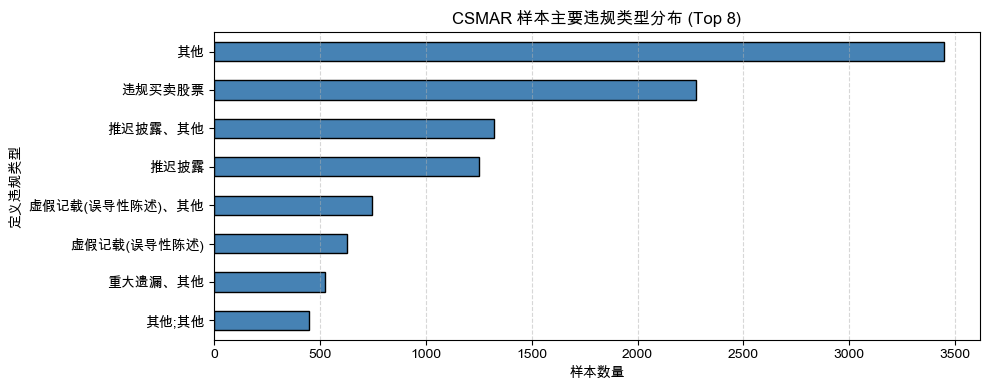

In [4]:
if 'ViolationType' in df_y.columns:
    violation_counts = df_y['ViolationType'].value_counts().head(8)
    
    plt.figure(figsize=(10, 4))
    violation_counts.sort_values().plot(kind='barh', color='steelblue', edgecolor='black')
    plt.title('CSMAR 样本主要违规类型分布 (Top 8)', fontsize=12)
    plt.xlabel('样本数量')
    plt.ylabel('定义违规类型')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
